# Steam Games Dataset - EDA
- **Author:** Vadim Egorov
- **Dataset:** Steam Games Dataset (3 CSV files) https://www.kaggle.com/datasets/muhammadaqeelkabir/steam-games-dataset-v2


This notebook inclides the EDA of Steam Games Dataset V2, since I love video games. I mainly play games through Steam platform and often browse store sections like "Top Sellers" and "Popular New Releases" hoping to find something that will interest me or my friends to play together. Since this dataset is specifically focused on Steam games, I am interested in looking at what characteristics are related to how successful and engaging games are on Steam.

So my main question for this dataset is: **What characteristics are related to the popularity, player engagement, and reception of games on Steam?**

## Three questions
1. Group comparison:
    - Question: Do average playtimes differ between video game genres?
    - Prediction: I expect genres such as Action and RPG to have higher average playtime than more casual genres because these games often have longer progression and more content.

2. Relationship between two numerical variables:
    - Question: Is there a relationship between the percentage of positive reviews and average playtime of a game?
    - Prediction: I expect a positive relationship because games that players enjoy and rate positively may also tend to keep players engaged for longer.

3. Creative question:
    - Question: Do free-to-play games differ from paid games in player engagement and popularity?
    - Prediction: I expect free-to-play games to have more current players and possibly higher average playtime because there is no initial cost preventing players from trying them.


# Imports

In [92]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind

# Exploratory Data Analysis 

## Load the dataset into a DataFrame

In [93]:
path = kagglehub.dataset_download("muhammadaqeelkabir/steam-games-dataset-v2")
print("Dataset downloaded to:", path)

df_extended = pd.read_csv(path + "/extended_steam_games.csv")
df_wikidata = pd.read_csv(path + "/steam_games_wikidata.csv")
df_raw = pd.read_csv(path + "/steamspy_raw.csv")

Dataset downloaded to: /Users/vadim/.cache/kagglehub/datasets/muhammadaqeelkabir/steam-games-dataset-v2/versions/3


## Understanding the dataset

- Number of rows and columns
- Numerical variables
- Categorical variables
- Meaning of the important variables that will be analyzed

In [94]:
print("Extended:")
print(df_extended.shape)
print(df_extended.dtypes)

print("\nWikidata:")
print(df_wikidata.shape)
print(df_wikidata.dtypes)

print("\nRaw SteamSpy:")
print(df_raw.shape)
print(df_raw.dtypes)

Extended:
(23100, 28)
appid                    int64
name                       str
developer                  str
publisher                  str
positive                 int64
negative                 int64
owners                     str
average_forever          int64
average_2weeks           int64
median_forever           int64
median_2weeks            int64
price                    int64
initialprice             int64
discount                 int64
ccu                      int64
release_date               str
required_age           float64
is_free                 object
short_description          str
supported_languages        str
platforms_windows       object
platforms_mac           object
platforms_linux         object
metacritic_score       float64
recommendations        float64
achievements           float64
genres                     str
categories                 str
dtype: object

Wikidata:
(128348, 8)
appid              int64
wikidata_name        str
esrb_rating          st

Looking at all of the available files in the dataset I think the only on I will be using is `df_extended` since it includes the most useful data.

In [95]:
# Number of rows and columns
shape = df_extended.shape
print("Shape:", shape)

# Numerical variables
numerical_vars = df_extended.select_dtypes(include=['number']).columns
print("\nNumerical variables:", list(numerical_vars))

# Categorical variables
categorical_vars = df_extended.select_dtypes(include=['object', 'string']).columns
print("\nCategorical variables:", list(categorical_vars))

Shape: (23100, 28)

Numerical variables: ['appid', 'positive', 'negative', 'average_forever', 'average_2weeks', 'median_forever', 'median_2weeks', 'price', 'initialprice', 'discount', 'ccu', 'required_age', 'metacritic_score', 'recommendations', 'achievements']

Categorical variables: ['name', 'developer', 'publisher', 'owners', 'release_date', 'is_free', 'short_description', 'supported_languages', 'platforms_windows', 'platforms_mac', 'platforms_linux', 'genres', 'categories']


In [96]:
df_extended.head(10)

,appid,name,developer,publisher,positive,negative,owners,average_forever,average_2weeks,median_forever,...,short_description,supported_languages,platforms_windows,platforms_mac,platforms_linux,metacritic_score,recommendations,achievements,genres,categories
0,730,Counter-Strike: Global Offensive,Valve,Valve,7642084,1173003,"100,000,000 .. 200,000,000",0,0,0,...,"For over two decades, Counter-Strike has offer...","Czech, Danish, Dutch, English<strong>*</strong...",True,False,True,NaN,5211693.0,1.0,"Action, Free To Play","Multi-player, Cross-Platform Multiplayer, Stea..."
1,1172470,Apex Legends,Respawn,Electronic Arts,668053,326926,"100,000,000 .. 200,000,000",0,0,0,...,"Apex Legends is the award-winning, free-to-pla...","English<strong>*</strong>, French<strong>*</st...",True,False,False,88.0,1580.0,12.0,"Action, Adventure, Free To Play","Multi-player, PvP, Online PvP, Co-op, Online C..."
2,578080,PUBG: BATTLEGROUNDS,PUBG Corporation,"KRAFTON, Inc.",1520457,1037487,"100,000,000 .. 200,000,000",0,0,0,...,"PUBG: BATTLEGROUNDS, the high-stakes winner-ta...","English, Korean, Simplified Chinese, French, G...",True,False,False,NaN,1762488.0,37.0,"Action, Adventure, Massively Multiplayer, Free...","Multi-player, PvP, Online PvP, Custom Volume C..."
3,1623730,Palworld,Pocketpair,Pocketpair,358266,22443,"50,000,000 .. 100,000,000",0,0,0,...,"Fight, farm, build and work alongside mysterio...","English, Simplified Chinese, Traditional Chine...",True,False,False,NaN,397504.0,75.0,"Action, Adventure, Indie, RPG","Single-player, Multi-player, Co-op, Online Co-..."
4,440,Team Fortress 2,Valve,Valve,1044264,117208,"50,000,000 .. 100,000,000",0,0,0,...,Nine distinct classes provide a broad range of...,"English<strong>*</strong>, Danish, Dutch, Finn...",True,False,True,92.0,47647.0,520.0,"Action, Free To Play","Multi-player, Cross-Platform Multiplayer, Stea..."
5,1938090,Call of Duty: Modern Warfare II,"Treyarch, Raven Software, Beenox, High Moon St...",Activision,419594,294520,"50,000,000 .. 100,000,000",0,0,0,...,The Call of Duty® experience supports Modern W...,"English<strong>*</strong>, French<strong>*</st...",True,False,False,NaN,410843.0,157.0,Action,"Single-player, Multi-player, PvP, Online PvP, ..."
6,1063730,New World: Aeternum,Amazon Games,Amazon Games,196798,90080,"50,000,000 .. 100,000,000",0,0,0,...,Experience a thrilling action RPG set on the s...,"English<strong>*</strong>, French<strong>*</st...",True,False,False,NaN,254000.0,133.0,"Action, Adventure, Massively Multiplayer, RPG","Multi-player, MMO, PvP, Online PvP, Co-op, Onl..."
7,2358720,Black Myth: Wukong,Game Science,Game Science,1111720,38378,"50,000,000 .. 100,000,000",0,0,0,...,Black Myth: Wukong is an action RPG rooted in ...,"English<strong>*</strong>, French, German, Spa...",True,False,False,NaN,875819.0,81.0,"Action, Adventure, RPG","Single-player, Steam Achievements, Full contro..."
8,271590,Grand Theft Auto V Legacy,Rockstar North,Rockstar Games,1739980,250576,"50,000,000 .. 100,000,000",0,0,0,...,Grand Theft Auto V for PC offers players the o...,"English<strong>*</strong>, French, Italian, Ge...",True,False,False,96.0,1890815.0,77.0,"Action, Adventure","Single-player, Multi-player, PvP, Online PvP, ..."
9,550,Left 4 Dead 2,Valve,Valve,940221,23762,"50,000,000 .. 100,000,000",0,0,0,...,"Set in the zombie apocalypse, Left 4 Dead 2 is...","Danish, Dutch, English<strong>*</strong>, Finn...",True,False,True,89.0,810590.0,101.0,Action,"Single-player, Multi-player, PvP, Online PvP, ..."


In [97]:
# average_forever is set to 0 in sample from above, verify if this is true for all samples
df_extended['average_forever'].isnull().sum()
print("Number of rows with average_forever = 0:", (df_extended['average_forever'] == 0).sum())

# check ccu - concurrent users
df_extended['ccu'].isnull().sum()
print("Number of rows with ccu = 0:", (df_extended['ccu'] == 0).sum())

Number of rows with average_forever = 0: 23100
Number of rows with ccu = 0: 11575


### Analysis of the variables

The dataset contains **23,100 Steam games** with numerical and categorical information about each one, from `extended_steam_games.csv`. Each row represents a game and `appid` is its unique ID in Steam.

**Numerical variables:** `positive`, `negative`, `average_forever`, `average_2weeks`, `median_forever`, `median_2weeks`, `price`, `initialprice`, `discount`, `ccu`, `required_age`, `metacritic_score`, `recommendations`, and `achievements`.

**Categorical variables:** `name`, `developer`, `publisher`, `owners`, `is_free`, `platforms_windows`, `platforms_mac`, `platforms_linux`, `genres`, and `categories`.

For this anlysis I expect to use only a few. In the next section I will decide on what to keep.

The variables I expect to matter most for my questions are:

* `name` - the name of the game.
* `genres` - the genres assigned to the game. Some games have more than one genre listed in the same string.
* `price` - the current price, stored in cents.
* `positive` / `negative` - the number of positive and negative reviews.
* `average_forever` - meant to be the average playtime for the game but it looks like every game is set to 0, might need to drop it.
* `ccu` - peak concurrent users, looks like at least half of the games is missing the data.
* `recommendations` - the number of Steam recommendations for the game, though the numbers look inconsistent with positive/negative counts for some games - will need to check.
* `is_free` - whether Steam marks the game as free to play.

`owners` is also useful for understanding popularity, but SteamSpy reports it as an estimated range (like `20,000 .. 50,000`) instead of an exact number, so I won't treat it as a normal numerical variable.

## Data quality checks

I'll check the raw dataset (`df_extended`) for:
* missing values
* duplicate rows
* unusual or problematic values

before deciding how to clean it and build the `df` I'll actually analyze.

In [98]:
# Missing values across all 28 raw columns before dropping anything
missing_count = df_extended.isnull().sum()
missing_percent = (missing_count / len(df_extended) * 100).round(2)

missing_values = pd.DataFrame({
    'Missing values': missing_count,
    'Percent missing': missing_percent
})

missing_values.sort_values(by='Percent missing', ascending=False).reset_index(drop=False)

,index,Missing values,Percent missing
0,metacritic_score,19394,83.96
1,categories,148,0.64
2,publisher,133,0.58
3,genres,109,0.47
4,release_date,102,0.44
5,developer,66,0.29
6,short_description,67,0.29
7,supported_languages,63,0.27
8,achievements,48,0.21
9,recommendations,48,0.21


In [99]:
# duplicate rows
duplicate_rows = df_extended.duplicated().sum()
print("Duplicate rows:", duplicate_rows)

# appid is supposed to be a unique id
duplicate_appids = df_extended['appid'].duplicated().sum()
print("Duplicate appid values:", duplicate_appids)

Duplicate rows: 489
Duplicate appid values: 492


In [100]:
# A few columns looked suspicious in head(10) like average_forever was 0 for every row shown,
# so check whether they actually vary across the whole dataset before deciding to drop them

print("Average columns unique values:")
print(df_extended[['average_forever', 'average_2weeks']].nunique())

print("\nMedian columns unique values:")
print(df_extended[['median_forever', 'median_2weeks']].nunique())

Average columns unique values:
average_forever    1
average_2weeks     1
dtype: int64

Median columns unique values:
median_forever    1
median_2weeks     1
dtype: int64


In [101]:
# Check for values that should not be negative
check_cols = ['price', 'positive', 'negative', 'ccu', 'recommendations', 'achievements']
for col in check_cols:
    print(col, "negative values:", (df_extended[col] < 0).sum())

price negative values: 0
positive negative values: 0
negative negative values: 0
ccu negative values: 0
recommendations negative values: 0
achievements negative values: 0


In [102]:
# Look at unusually large values
print("Games with the highest number of current players (ccu):")
df_extended[['name', 'ccu']].sort_values(by='ccu', ascending=False).head(10)

Games with the highest number of current players (ccu):


,name,ccu
0,Counter-Strike: Global Offensive,1013936
2,PUBG: BATTLEGROUNDS,314682
479,ELDEN RING NIGHTREIGN,163599
25,Rust,143870
1,Apex Legends,124262
19,Wallpaper Engine,91184
1290,DELTARUNE,83936
8,Grand Theft Auto V Legacy,67851
5,Call of Duty: Modern Warfare II,67419
49,NARAKA: BLADEPOINT,66954


In [103]:
print("\nGames with the most positive reviews:")
df_extended[['name', 'positive', 'negative']].sort_values(by='positive', ascending=False).head(10)


Games with the most positive reviews:


,name,positive,negative
0,Counter-Strike: Global Offensive,7642084,1173003
8,Grand Theft Auto V Legacy,1739980,250576
2,PUBG: BATTLEGROUNDS,1520457,1037487
17,Terraria,1373979,35494
24,Tom Clancy's Rainbow Six Siege,1172854,225730
22,Garry's Mod,1122546,37161
7,Black Myth: Wukong,1111720,38378
25,Rust,1071135,156649
4,Team Fortress 2,1044264,117208
16,ELDEN RING,981540,75137


In [104]:
# recommendations comes from a separate lookup (the dataset's own description says it maps
# "top games" from SteamSpy to the official Steam Storefront API), not the same source as
# positive/negative - check whether it actually agrees with those before using it
print("Correlation between recommendations and positive:", df_extended['recommendations'].corr(df_extended['positive']).round(2))

mismatch = df_extended[(df_extended['recommendations'] == 0) & (df_extended['positive'] > 1000)]
print("Games with recommendations = 0 but over 1,000 positive reviews:", len(mismatch))

print("\nSome of those games:")
print(mismatch[['name', 'positive', 'recommendations']].sort_values(by='positive', ascending=False).head(5))

print("\nmetacritic_score missing rate when recommendations == 0:",
      round(df_extended.loc[df_extended['recommendations'] == 0, 'metacritic_score'].isna().mean() * 100, 1), "%")
print("metacritic_score missing rate when recommendations > 0:",
      round(df_extended.loc[df_extended['recommendations'] > 0, 'metacritic_score'].isna().mean() * 100, 1), "%")

Correlation between recommendations and positive: 0.96
Games with recommendations = 0 but over 1,000 positive reviews: 582

Some of those games:
                       name  positive  recommendations
128  SCP: Secret Laboratory    195923              0.0
150               Crab Game    139538              0.0
132         Dota Underlords     74753              0.0
395         Fallout Shelter     65847              0.0
308    Supermarket Together     63994              0.0

metacritic_score missing rate when recommendations == 0: 98.1 %
metacritic_score missing rate when recommendations > 0: 73.8 %


In [105]:
# genres sometimes lists non-English translations of the same genre (e.g. Action in other languages),
# check the first listed genre across the whole dataset to see how messy this actually is
first_genre_raw = df_extended['genres'].dropna().str.split(',').str[0].str.strip()
print(first_genre_raw.value_counts())

genres
Action                   10238
Adventure                 5123
Casual                    2823
Indie                     2126
Simulation                 627
RPG                        592
Strategy                   496
Free To Play               334
Racing                     202
Massively Multiplayer       76
Utilities                   71
Animation & Modeling        58
Sports                      54
Violent                     50
Design & Illustration       22
Audio Production            19
Nudity                      12
Education                   12
Gore                         9
Sexual Content               9
Экшены                       7
Ação                         6
Video Production             6
Software Training            3
Game Development             3
Early Access                 3
Accounting                   3
Aventura                     2
Estratégia                   1
冒险                           1
Simulação                    1
休闲                           1
P

In [106]:
# is_free is Steam's own free/paid flag, price is the current price in cents - check whether they agree
price_label = (df_extended['price'] == 0).map({True: 'Price = $0', False: 'Price > $0'})
is_free_label = df_extended['is_free'].map({True: 'is_free = True', False: 'is_free = False'})
is_free_label = is_free_label.fillna('is_free = Missing')

ct = pd.crosstab(is_free_label, price_label, margins=True, margins_name='Total')
ct.index.name = None
ct.columns.name = None
print(ct)

                   Price = $0  Price > $0  Total
is_free = False          1442       18605  20047
is_free = Missing          10          38     48
is_free = True           2948          57   3005
Total                    4400       18700  23100


In [107]:
# distribution of games by the platforms like windows, mac, linux
platform_distribution = df_extended['platforms_windows'].value_counts()
print("\nDistribution of games by platform:")
print(platform_distribution)


Distribution of games by platform:
platforms_windows
True     23046
False        6
Name: count, dtype: int64


### Data quality findings and how I handled them

**Missing values:**
Most of the missing data is concentrated in `metacritic_score` (84%), with everything else under 1%. I care most about `genres`, `price`, `positive`, `negative`, and `ccu` for my questions, so missing values in less important columns aren't a big concern. Instead of dropping every row that has any missing value anywhere, I'll only drop rows for a specific analysis if the variable that analysis needs is missing.

**Duplicate observations:**
There are 489 fully duplicate rows and 492 duplicate `appid` values. Since `appid` is supposed to be a unique Steam application ID, these are the same game listed more than once, not real repeated observations, so I'll remove them with `drop_duplicates()`.

**Columns I'm dropping, and why:**
* `average_forever`, `average_2weeks`, `median_forever`, `median_2weeks` - each has only 1 unique value across all 23,100 rows (they're 0 for every game). SteamSpy lost access to real playtime data after Valve restricted its API around 2018, so these columns carry no information anymore.
* `metacritic_score` - missing for about 84% of games, too sparse to use as a main variable.
* `platforms_windows`, `platforms_mac`, `platforms_linux` - `platforms_windows` True for 23,046 of 23,100 games (99.8%). Almost every Steam game supports Windows, so it doesn't separate games from each other.
* `required_age` - It's not related to my questions.
* `short_description` - free text, not something I can run statistics on.
* `categories` - a messy multi-value tag list (things like "Steam Achievements", "Full controller support", "PvP" all mixed together in one string), similar to `genres` but noisier, and I'm not using it for any of my three questions.
* `recommendations` - I originally planned to use this as my engagement variable, but the check above shows it's unreliable: it only correlates 0.96 with `positive` instead of matching it closely (a Steam recommendation *is* a positive review, so it should track it), and hundreds of clearly popular games (SCP: Secret Laboratory, Dota Underlords, Fallout Shelter) show `recommendations = 0` alongside thousands of positive reviews. `metacritic_score` is also missing far more often when `recommendations = 0` (98% vs. 74%), which tells me this column was only filled in for a subset of "top games," and 0 mostly means "wasn't looked up," not "zero recommendations." On top of that, even when it is populated, it's basically just re-measuring `positive` from a less complete source. I'm dropping it and using `ccu` as my engagement variable instead.

**Columns I'm keeping:** `appid`, `name`, `developer`, `publisher`, `positive`, `negative`, `owners`, `price`, `initialprice`, `discount`, `ccu`, `release_date`, `is_free`, `supported_languages`, `achievements`, `genres`.

**Other unusual/problematic values:**
* Some games have extremely high `ccu` and review counts (a small number of very popular games like CS:GO or PUBG dominate). These are real values, not errors - a handful of massively popular Steam games really do have far more players and reviews than a typical game. I'm not removing them, but I'll need to keep this skew in mind since it can pull the mean well above the median for these variables.
* The dataset also has many games with zero current players or very few reviews. These are not missing or incorrect either - a game can legitimately have no one playing it right now.
* `genres` sometimes lists non-English translations of the same genre (e.g. `Экшены`/`Ação` instead of "Action") as the first entry for a handful of games. My `primary_genre` (first listed genre) will translate the primary genres from the games that havbe a genre in a non-English language.
* `is_free` and `price == 0` disagree for about 1,499 games (1,442 priced $0 but flagged as not free, 57 flagged free but priced above $0). I'm going to derive my `price_type` variable from `price == 0` instead of `is_free`, since `price` has no missing values and is an objective, always-present threshold.

**What this means for my questions:**
Since `average_forever`/`median_forever` are dead and `recommendations` turned out to be unreliable, my original Q1 (genre vs. average playtime) and Q2 (reviews vs. average playtime) can't be answered as originally written - there's no variation to compare or correlate with, and my first replacement idea didn't hold up either. I'll rework both around `ccu` instead, which is my one reliable numeric stand-in for player engagement and popularity.

In [138]:
drop_cols = [
    'average_forever', 'average_2weeks', 'median_forever', 'median_2weeks',
    'metacritic_score', 'platforms_windows', 'platforms_mac', 'platforms_linux', 'required_age',
    'short_description', 'categories', 'recommendations', 'initialprice', 'discount'
]

df = df_extended.drop_duplicates().drop(columns=drop_cols)

print("Shape after removing duplicates and dropping columns:", df.shape)
print("\nRemaining columns:", list(df.columns))

Shape after removing duplicates and dropping columns: (22611, 14)

Remaining columns: ['appid', 'name', 'developer', 'publisher', 'positive', 'negative', 'owners', 'price', 'ccu', 'release_date', 'is_free', 'supported_languages', 'achievements', 'genres']


In [139]:
# Create a few variables that will be useful for the analysis

# SteamSpy stores price in cents, convert it to dollars
df['price_usd'] = df['price'] / 100

# Total number of reviews and percentage of positive reviews
df['total_reviews'] = df['positive'] + df['negative']
df['positive_review_ratio'] = np.where(
    df['total_reviews'] > 0,
    (df['positive'] / df['total_reviews']) * 100,
    np.nan
)

# Separate games into free and paid groups
df['price_type'] = np.where(df['price'] == 0, 'Free', 'Paid')

# Some games have multiple genres, use the first listed genre for simple group comparisons
df['primary_genre'] = df['genres'].str.split(',').str[0].str.strip()

# rename Экшены, Ação to "Action" for consistency
df['primary_genre'] = df['primary_genre'].replace({'Экшены': 'Action', 'Ação': 'Action'})

# rename Aventura to "Adventure" for consistency
df['primary_genre'] = df['primary_genre'].replace({'Aventura': 'Adventure'})

# rename Estratégia to "Strategy" for consistency
df['primary_genre'] = df['primary_genre'].replace({'Estratégia': 'Strategy'})

# rename 冒险 to "Adventure" for consistency
df['primary_genre'] = df['primary_genre'].replace({'冒险': 'Adventure'})

# rename Simulação to "Simulation" for consistency
df['primary_genre'] = df['primary_genre'].replace({'Simulação': 'Simulation'})

# rename 休闲 to "Casual" for consistency
df['primary_genre'] = df['primary_genre'].replace({'休闲': 'Casual'})


**Variables I derived after cleaning:**

* `price_usd` - `price` converted from cents to dollars.
* `total_reviews` / `positive_review_ratio` - total number of reviews and the percentage of those reviews that are positive.
* `price_type` - Free vs Paid, based on whether `price` is 0.
* `primary_genre` - the first genre listed in `genres`, used for simpler group comparisons since many games have multiple genres.

In [140]:
df.head(10)

,appid,name,developer,publisher,positive,negative,owners,price,ccu,release_date,is_free,supported_languages,achievements,genres,price_usd,total_reviews,positive_review_ratio,price_type,primary_genre
0,730,Counter-Strike: Global Offensive,Valve,Valve,7642084,1173003,"100,000,000 .. 200,000,000",0,1013936,"21 Aug, 2012",True,"Czech, Danish, Dutch, English<strong>*</strong...",1.0,"Action, Free To Play",0.00,8815087,86.693234,Free,Action
1,1172470,Apex Legends,Respawn,Electronic Arts,668053,326926,"100,000,000 .. 200,000,000",0,124262,"4 Nov, 2020",True,"English<strong>*</strong>, French<strong>*</st...",12.0,"Action, Adventure, Free To Play",0.00,994979,67.142422,Free,Action
2,578080,PUBG: BATTLEGROUNDS,PUBG Corporation,"KRAFTON, Inc.",1520457,1037487,"100,000,000 .. 200,000,000",0,314682,"21 Dec, 2017",True,"English, Korean, Simplified Chinese, French, G...",37.0,"Action, Adventure, Massively Multiplayer, Free...",0.00,2557944,59.440590,Free,Action
3,1623730,Palworld,Pocketpair,Pocketpair,358266,22443,"50,000,000 .. 100,000,000",2999,18028,"Jul 9, 2026",False,"English, Simplified Chinese, Traditional Chine...",75.0,"Action, Adventure, Indie, RPG",29.99,380709,94.104946,Paid,Action
4,440,Team Fortress 2,Valve,Valve,1044264,117208,"50,000,000 .. 100,000,000",0,43819,"10 Oct, 2007",True,"English<strong>*</strong>, Danish, Dutch, Finn...",520.0,"Action, Free To Play",0.00,1161472,89.908668,Free,Action
5,1938090,Call of Duty: Modern Warfare II,"Treyarch, Raven Software, Beenox, High Moon St...",Activision,419594,294520,"50,000,000 .. 100,000,000",3849,67419,"Oct 27, 2022",False,"English<strong>*</strong>, French<strong>*</st...",157.0,Action,38.49,714114,58.757285,Paid,Action
6,1063730,New World: Aeternum,Amazon Games,Amazon Games,196798,90080,"50,000,000 .. 100,000,000",5999,5583,"Sep 28, 2021",False,"English<strong>*</strong>, French<strong>*</st...",133.0,"Action, Adventure, Massively Multiplayer, RPG",59.99,286878,68.599893,Paid,Action
7,2358720,Black Myth: Wukong,Game Science,Game Science,1111720,38378,"50,000,000 .. 100,000,000",5999,15004,"Aug 19, 2024",False,"English<strong>*</strong>, French, German, Spa...",81.0,"Action, Adventure, RPG",59.99,1150098,96.663067,Paid,Action
8,271590,Grand Theft Auto V Legacy,Rockstar North,Rockstar Games,1739980,250576,"50,000,000 .. 100,000,000",0,67851,"13 Apr, 2015",False,"English<strong>*</strong>, French, Italian, Ge...",77.0,"Action, Adventure",0.00,1990556,87.411758,Free,Action
9,550,Left 4 Dead 2,Valve,Valve,940221,23762,"50,000,000 .. 100,000,000",999,25122,"16 Nov, 2009",False,"Danish, Dutch, English<strong>*</strong>, Finn...",101.0,Action,9.99,963983,97.535019,Paid,Action


## Descriptive Statistics:

For the numerical variables important to my analysis, report appropriate descriptive statistics, including:
* Mean
* Median
* Standard deviation
* Minimum and maximum
* Quartiles

I'll compute these for `price_usd`, `positive`, `negative`, `total_reviews`, `positive_review_ratio`, `ccu`, and `achievements`, since these are the numerical variables I'm actually using across my three questions.

In [110]:
# mean, std, min, 25/50/75% quartiles, and max all come out of describe() in one table
# (the 50% row is the median)
stats_cols = [
    'price_usd', 'positive', 'negative', 'total_reviews',
    'positive_review_ratio', 'ccu', 'achievements'
]
df[stats_cols].describe()

,price_usd,positive,negative,total_reviews,positive_review_ratio,ccu,achievements
count,22611.000000,2.261100e+04,2.261100e+04,2.261100e+04,22584.000000,2.261100e+04,22566.000000
mean,9.078644,5.510384e+03,8.957849e+02,6.406169e+03,76.792167,2.525984e+02,35.005318
std,10.710730,6.369662e+04,1.209308e+04,7.380434e+04,18.390366,7.511745e+03,215.252930
min,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000
25%,0.990000,5.000000e+01,1.500000e+01,7.400000e+01,67.372007,0.000000e+00,0.000000
50%,4.990000,2.930000e+02,7.600000e+01,3.970000e+02,80.803305,1.000000e+00,14.000000
75%,13.990000,1.339500e+03,2.720000e+02,1.653000e+03,90.339787,7.000000e+00,34.000000
max,199.990000,7.642084e+06,1.173003e+06,8.815087e+06,100.000000,1.013936e+06,9821.000000


In [111]:
# skew() > 0 means a right-skewed (long tail on the high end) distribution, < 0 means left-skewed
print(df[stats_cols].skew().round(2))

print("\nGames below 50% positive review ratio:", (df['positive_review_ratio'] < 50).sum())

price_usd                  2.55
positive                  81.06
negative                  72.02
total_reviews             80.81
positive_review_ratio     -1.32
ccu                      113.33
achievements              22.16
dtype: float64

Games below 50% positive review ratio: 1836


### Distribution of `positive_review_ratio`

I picked `positive_review_ratio` to look at more closely. The mean is about 76.8% but the median is about 80.8% - the mean sitting below the median is the signature of a left-skewed (negatively skewed) distribution, which matches the skew statistic (-1.32). Most games cluster between the 25th and 75th percentile (about 67% to 90%), so a typical Steam game is fairly well received.

The skew comes from a tail of poorly-reviewed games pulling the low end down: about 1,836 games (roughly 8% of the dataset) sit below 50%, dragging the mean below the bulk of the distribution, which is bunched up near the top. Since the variable is bounded between 0 and 100, it doesn't have the same kind of extreme high-value outliers as `ccu` or `positive` reviews - but there is a pileup right at 100% (and at 0%) that comes from games with very few total reviews, where one or two reviews can push the ratio straight to an extreme. So the ratio is less reliable for low-review games - a game sitting at 100% based on 2 reviews doesn't mean the same thing as one sitting at 100% based on 10,000 reviews.

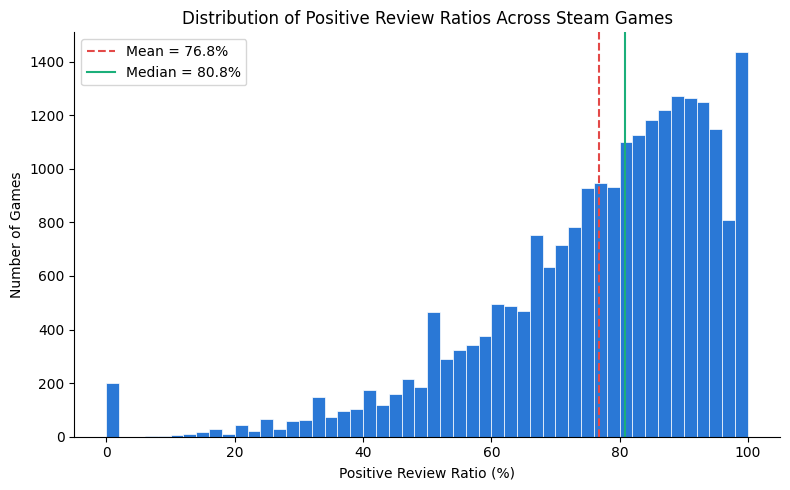

In [112]:
mean_ratio = df['positive_review_ratio'].mean()
median_ratio = df['positive_review_ratio'].median()

fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(
    df['positive_review_ratio'].dropna(),
    bins=50, range=(0, 100),
    color='#2a78d6', edgecolor='white', linewidth=0.5
)

ax.axvline(mean_ratio, color='#e34948', linestyle='--', linewidth=1.5, label=f'Mean = {mean_ratio:.1f}%')
ax.axvline(median_ratio, color='#1baf7a', linestyle='-', linewidth=1.5, label=f'Median = {median_ratio:.1f}%')

ax.set_title('Distribution of Positive Review Ratios Across Steam Games')
ax.set_xlabel('Positive Review Ratio (%)')
ax.set_ylabel('Number of Games')
ax.legend()

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

The chart backs up the stats: the bars build up gradually from the low end and peak in the high-80s/low-90s, with the mean line sitting to the left of the median line - a visual left skew. Interestingly, the single tallest bar isn't in that 88-92% peak, it's the very last bar at 98-100% - that's the pileup of low-review-count games I mentioned above (a game with 3 positive reviews and 0 negative ones hits 100% instantly), not a sign that "perfect" is actually the most common outcome.

In [113]:
# quick check that the derived positive_review_ratio came out valid
invalid_ratio = ((df['positive_review_ratio'] < 0) | (df['positive_review_ratio'] > 100)).sum()
print("Positive review ratios outside 0-100:", invalid_ratio)
print("Games with no reviews (ratio is NaN):", df['positive_review_ratio'].isna().sum())

print("\nGames with the most total reviews:")
df[['name', 'total_reviews', 'positive_review_ratio']].sort_values(by='total_reviews', ascending=False).head(10)

Positive review ratios outside 0-100: 0
Games with no reviews (ratio is NaN): 27

Games with the most total reviews:


,name,total_reviews,positive_review_ratio
0,Counter-Strike: Global Offensive,8815087,86.693234
2,PUBG: BATTLEGROUNDS,2557944,59.440590
8,Grand Theft Auto V Legacy,1990556,87.411758
17,Terraria,1409473,97.481754
24,Tom Clancy's Rainbow Six Siege,1398584,83.860104
25,Rust,1227784,87.241323
4,Team Fortress 2,1161472,89.908668
22,Garry's Mod,1159707,96.795656
7,Black Myth: Wukong,1150098,96.663067
16,ELDEN RING,1056677,92.889312


In [114]:
# total games, appid is a unique Steam application ID
total_games = df['appid'].nunique()
print("Total games:", total_games)

Total games: 22608


In [115]:
genre_list = df['primary_genre'].dropna().unique()
publisher_list = df['publisher'].dropna().unique()
developer_list = df['developer'].dropna().unique()

total_genres = len(genre_list)
total_publishers = len(publisher_list)
total_developers = len(developer_list)

print("Primary genres count:", total_genres)
print("Publishers count:", total_publishers)
print("Developers count:", total_developers)

print("\nPrimary genres:", genre_list)

Primary genres count: 26
Publishers count: 12060
Developers count: 15155

Primary genres: ['Action' 'Casual' 'Adventure' 'Indie' 'RPG' 'Simulation' 'Strategy'
 'Racing' 'Massively Multiplayer' 'Animation & Modeling' 'Free To Play'
 'Audio Production' 'Utilities' 'Violent' 'Software Training' 'Sports'
 'Game Development' 'Nudity' 'Design & Illustration' 'Early Access' 'Gore'
 'Education' 'Sexual Content' 'Accounting' 'Video Production'
 'Photo Editing']


In [116]:
# get price range in dollars
print("Price range: $", df['price_usd'].min(), "to $", df['price_usd'].max())

# get positive review ratio range
print("Positive review ratio range:", df['positive_review_ratio'].min(), "to", df['positive_review_ratio'].max())

# ccu represents peak concurrent users yesterday - my engagement variable now that average_forever is gone
print("CCU range:", df['ccu'].min(), "to", df['ccu'].max())

Price range: $ 0.0 to $ 199.99
Positive review ratio range: 0.0 to 100.0
CCU range: 0 to 1013936


In [117]:
# Check the count of each primary genre, including NaN values
print(df['primary_genre'].value_counts(dropna=False))

primary_genre
Action                   10053
Adventure                 5002
Casual                    2743
Indie                     2083
Simulation                 620
RPG                        587
Strategy                   488
Free To Play               328
Racing                     199
NaN                        105
Massively Multiplayer       75
Utilities                   71
Animation & Modeling        56
Sports                      53
Violent                     49
Design & Illustration       21
Audio Production            19
Education                   12
Nudity                      10
Gore                         9
Sexual Content               9
Video Production             6
Software Training            3
Game Development             3
Early Access                 3
Accounting                   3
Photo Editing                1
Name: count, dtype: int64


In [118]:
# Check how many games are free compared with paid
print(df['price_type'].value_counts(dropna=False))

price_type
Paid    18298
Free     4313
Name: count, dtype: int64


## Visual exploration

### **1. Histogram** 
- already built in the Descriptive Statistics section above (`positive_review_ratio` distribution with mean/median lines)

### **2. Boxplot**
- `positive_review_ratio` split by `price_type` (Free vs. Paid).

/var/folders/w1/8p7_fln1257ft8wkxpm8g7d00000gn/T/ipykernel_45114/22316062.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=groups, patch_artist=True, widths=0.5,


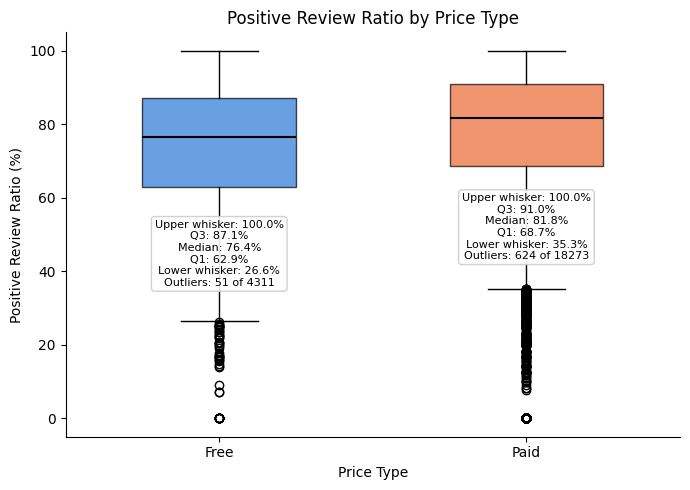

In [119]:
groups = ['Free', 'Paid']
data = [df.loc[df['price_type'] == g, 'positive_review_ratio'].dropna() for g in groups]

fig, ax = plt.subplots(figsize=(7, 5))

bp = ax.boxplot(data, labels=groups, patch_artist=True, widths=0.5,
                 medianprops=dict(color='black', linewidth=1.5))

for patch, color in zip(bp['boxes'], ['#2a78d6', '#eb6834']):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

# label each box with its actual median, quartiles, whiskers, and outlier count
# (whiskers/outliers use matplotlib's default rule: outside 1.5 * IQR from the box)
for i, g in enumerate(groups):
    sub = data[i]
    q1, median, q3 = sub.quantile([0.25, 0.5, 0.75])
    iqr = q3 - q1
    lower_fence, upper_fence = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    whisker_low = sub[sub >= lower_fence].min()
    whisker_high = sub[sub <= upper_fence].max()
    n_outliers = ((sub < lower_fence) | (sub > upper_fence)).sum()

    stats_text = (
        f"Upper whisker: {whisker_high:.1f}%\n"
        f"Q3: {q3:.1f}%\n"
        f"Median: {median:.1f}%\n"
        f"Q1: {q1:.1f}%\n"
        f"Lower whisker: {whisker_low:.1f}%\n"
        f"Outliers: {n_outliers} of {len(sub)}"
    )
    y_pos = (whisker_low + q1) / 2
    ax.text(
        i + 1, y_pos, stats_text,
        ha='center', va='center', fontsize=8,
        bbox=dict(boxstyle='round', facecolor='white', edgecolor='#cccccc', alpha=0.9)
    )

ax.set_title('Positive Review Ratio by Price Type')
ax.set_xlabel('Price Type')
ax.set_ylabel('Positive Review Ratio (%)')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

Paid games have a noticeably higher review ratio than free games: the median for Paid is about 81.8% versus 76.4% for Free, and the whole Paid box sits higher (Q1-Q3 of 68.7-91.0% vs. 62.9-87.1% for Free). That's the opposite of what I predicted for Q3 - I expected free games to have an easier time pleasing players since there's no cost involved, but paid games actually get rated better on average. Both groups have a cluster of low outliers (games with unusually bad reception), but proportionally more of the Paid group falls below the lower whisker (about 3.4% of paid games vs. 1.2% of free games) - so "paid reviews better" is true for the typical/median game, not universally true.

### **3. Bar chart**
- average `ccu` per game across the 8 most common genres (grouped with `groupby()`).

In [120]:
# Get the top 8 genres, exclude free-to-play and Massively Multiplayer Genres
top_genres = df[(df['primary_genre'] != 'Free To Play') & (df['primary_genre'] != 'Massively Multiplayer')]['primary_genre'].value_counts().nlargest(8).index.tolist()
print("\nTop 8 genres:")
print(top_genres)


Top 8 genres:
['Action', 'Adventure', 'Casual', 'Indie', 'Simulation', 'RPG', 'Strategy', 'Racing']


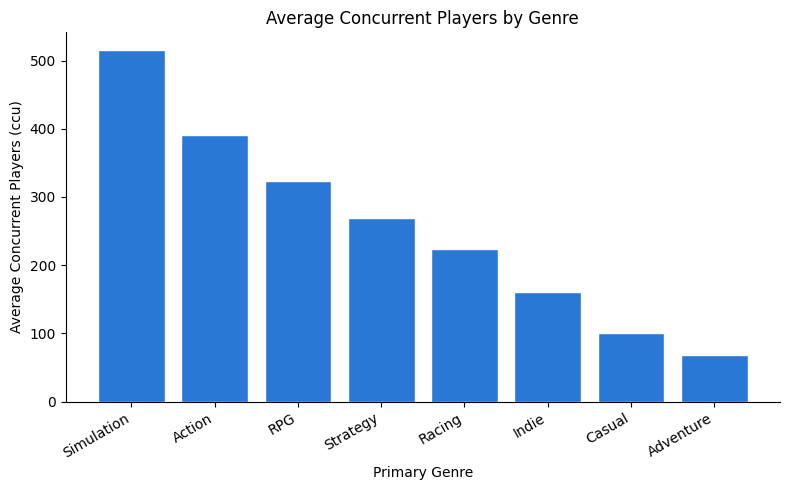

In [121]:
# the 8 most common real genres, ordered by average ccu (descending)
genre_means = (
    df[df['primary_genre'].isin(top_genres)]
    .groupby('primary_genre')['ccu']
    .mean()
    .reindex(top_genres)
    .sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(genre_means.index, genre_means.values, color='#2a78d6', edgecolor='white')

ax.set_title('Average Concurrent Players by Genre')
ax.set_xlabel('Primary Genre')
ax.set_ylabel('Average Concurrent Players (ccu)')
plt.xticks(rotation=30, ha='right')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

Simulation and Action average the highest number of concurrent players (about 516 and 391), with RPG and Strategy close behind. Casual and Adventure sit much lower (about 101 and 68). `ccu` is also heavily right-skewed (skew stat of 113!), and Action is a good example of why that matters: its mean of 391 is pulled way up by a handful of massive hits, since its *median* ccu is 0 - more than half of all Action games have nobody currently playing them. So this chart mostly shows which genres contain the biggest current hits, not what a "typical" game in that genre is experiencing right now.

### **4. Scatter plot**
- `positive_review_ratio` vs. `ccu`, my reworked Q2 (reviews vs. engagement). I originally tried this with `recommendations`, but that turned out to be unreliable (see the data quality section), so I switched to `ccu`.

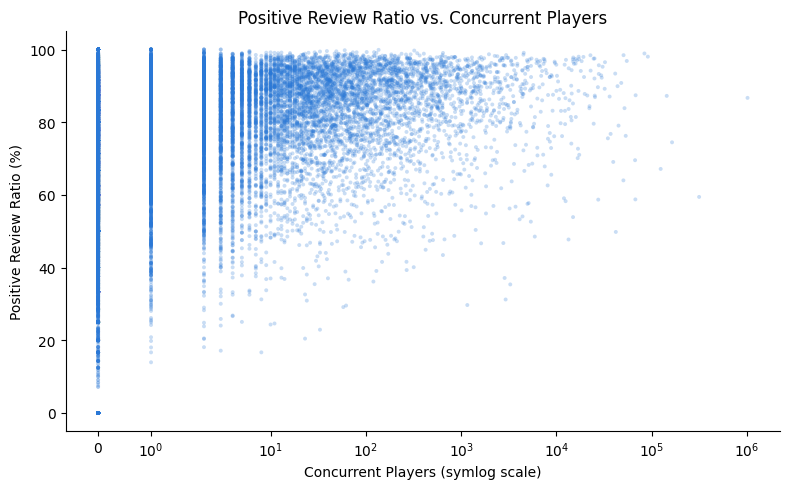

Correlation (raw ccu): 0.012
Correlation (log-transformed ccu): 0.234


In [122]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(
    df['ccu'], df['positive_review_ratio'],
    s=8, alpha=0.25, color='#2a78d6', edgecolors='none'
)

# symlog acts like a log scale for large values but stays linear near 0, so the ~11,200
# games with 0 concurrent players are still visible instead of being dropped
ax.set_xscale('symlog')

ax.set_title('Positive Review Ratio vs. Concurrent Players')
ax.set_xlabel('Concurrent Players (symlog scale)')
ax.set_ylabel('Positive Review Ratio (%)')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

raw_corr = df['ccu'].corr(df['positive_review_ratio'])
log_corr = np.log1p(df['ccu']).corr(df['positive_review_ratio'])
print("Correlation (raw ccu):", round(raw_corr, 3))
print("Correlation (log-transformed ccu):", round(log_corr, 3))

At first glance this looks like a mostly flat cloud, and the raw correlation is only 0.012. But `ccu` is extremely skewed (skew stat of 113), so a raw correlation badly understates any real relationship - it's dominated by a handful of massive outliers instead of the overall pattern. Once I log-transform `ccu`, the correlation jumps to 0.234 - a real but still modest positive relationship. That actually leans toward supporting my Q2 prediction after all, just much more weakly than I expected, and only visible once I account for the skew properly. Games with very few concurrent players still span a wide range of review ratios, but the most-played games are much more consistently well-reviewed - extremely popular games are rarely badly reviewed, even if plenty of small, barely-played games are still well reviewed too.

### **5. Additional visualization**
- the free/paid split within each genre (stacked bar), since the boxplot above found a price-type effect on reviews and I want to see whether that's confounded with genre.

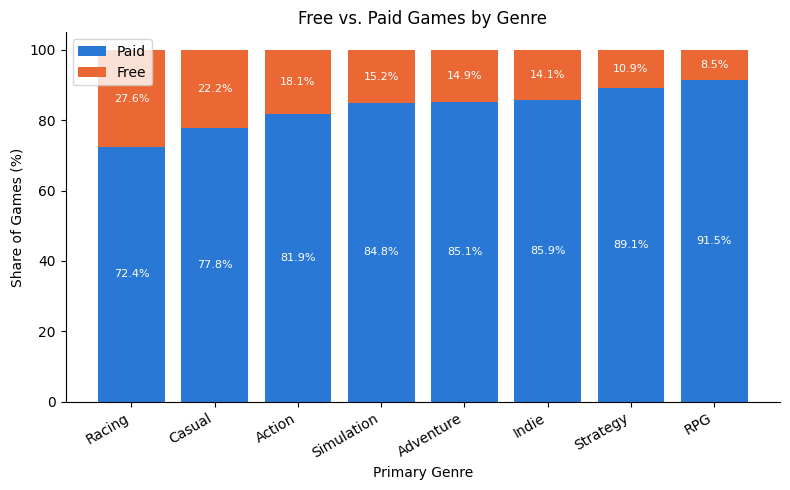

In [123]:
# excluding the "Free To Play" genre bucket - every game listed under it is free by
# definition, so that comparison would be circular
genre_order = ['Racing', 'Casual', 'Action', 'Simulation', 'Adventure', 'Indie', 'Strategy', 'RPG']
genre_price = (
    pd.crosstab(df['primary_genre'], df['price_type'], normalize='index') * 100
).reindex(genre_order)

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(genre_price.index, genre_price['Paid'], color='#2a78d6', label='Paid')
ax.bar(genre_price.index, genre_price['Free'], bottom=genre_price['Paid'], color='#eb6834', label='Free')

# label each segment with its exact share
for i, genre in enumerate(genre_order):
    paid_val = genre_price.loc[genre, 'Paid']
    free_val = genre_price.loc[genre, 'Free']
    ax.text(i, paid_val / 2, f'{paid_val:.1f}%', ha='center', va='center', fontsize=8, color='white')
    ax.text(i, paid_val + free_val / 2, f'{free_val:.1f}%', ha='center', va='center', fontsize=8, color='white')

ax.set_title('Free vs. Paid Games by Genre')
ax.set_xlabel('Primary Genre')
ax.set_ylabel('Share of Games (%)')
ax.legend()
plt.xticks(rotation=30, ha='right')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

The free-to-play share varies a lot by genre: Racing (27.6%) and Casual (22.2%) have the largest free share, while RPG (8.5%) and Strategy (10.9%) are almost entirely paid. That's a real confound for the boxplot above - RPG, the genre least likely to be free, is also one of the genres that would pull the "Paid" group's median review ratio up, so some of that free-vs-paid review gap could actually be a genre effect wearing a price-type costume. I'd want to control for genre before trusting the price-type comparison on its own.

## Group Comparison:

I'll compare `ccu` across the 8 most common genres, building on the bar chart from the Visual Exploration section - but this time with the mean and median side by side.

In [134]:
top_genres = ['RPG', 'Action', 'Racing', 'Simulation', 'Strategy', 'Indie', 'Adventure', 'Casual']

genre_comparison = (
    df[df['primary_genre'].isin(top_genres)]
    .groupby('primary_genre')['ccu']
    .agg(['mean', 'median'])
    .reindex(top_genres)
    .round(1)
)

# add a column for the number of games in each genre
genre_comparison['count'] = df[df['primary_genre'].isin(top_genres)].groupby('primary_genre').size().reindex(top_genres)

# add a column for the percentage of free games in each genre
genre_comparison['percent_free'] = (
    df[df['primary_genre'].isin(top_genres)]
    .groupby('primary_genre')['price_type']
    .apply(lambda x: (x == 'Free').mean() * 100)
    .reindex(top_genres)
)

# add a column for the percentage of games with 0 concurrent players in each genre
genre_comparison['zero_ccu_percent'] = (
    df[df['primary_genre'].isin(top_genres)]
    .groupby('primary_genre')['ccu']
    .apply(lambda x: (x == 0).mean() * 100)
    .reindex(top_genres)
)

genre_comparison

,mean,median,count,percent_free,zero_ccu_percent
primary_genre,,,,,
RPG,323.5,4.0,587,8.517888,29.131175
Action,391.1,0.0,10053,18.143838,51.536855
Racing,223.2,7.0,199,27.638191,28.140704
Simulation,515.6,6.5,620,15.161290,25.967742
Strategy,268.9,4.0,488,10.860656,30.532787
Indie,160.9,1.0,2083,14.114258,46.615458
Adventure,67.7,0.0,5002,14.854058,53.178729
Casual,101.1,0.0,2743,22.201969,54.903390


Looking at mean and median together for each genre reveals something the bar chart alone couldn't: how *concentrated* each genre's popularity actually is.

* **Casual** has a mean of about 101 concurrent players but a **median of 0** - 54.9% of all Casual games have nobody currently playing them. The genre's average is being carried by a small number of hits.
* **Action** shows the exact same pattern: a mean of about 391 concurrent players but a median of 0 (51.5% of Action games have zero). Most Action games have nobody playing them right now, even though the genre as a whole (thanks to games like CS:GO) dominates total player activity.
* **Racing**, by contrast, has a mean (223) and median (7) that are much closer together - its success is spread more evenly across its pool of titles, 199 games, rather than being carried by one or two blockbusters.

This is exactly what I couldn't see just by scrolling through rows of the raw dataset - I needed the group-by aggregation to notice that "Action has high average engagement" actually means "Action has a few enormous hits and a long tail of ignored games," while "Racing has high average engagement" means something closer to "a typical Racing game does reasonably well." Two genres can land on the same bar-chart height for completely different reasons, and only comparing mean vs. median per group exposes that.

## Relationships and correlation:

I'm using `positive_review_ratio` and `ccu` again here since that's my Q2 pair. I already built the scatter for it in the Visual Exploration section, so I won't duplicate the chart, just formalize the correlation value and answer the questions above. Then I'll build a correlation heatmap across all 7 of my numeric variables to check whether anything else in the dataset is more strongly related.

In [125]:
raw_corr = df['positive_review_ratio'].corr(df['ccu'])
log_corr = df['positive_review_ratio'].corr(np.log1p(df['ccu']))
print(f"Correlation (raw ccu): {raw_corr:.3f}")
print(f"Correlation (log-transformed ccu): {log_corr:.3f}")

Correlation (raw ccu): 0.012
Correlation (log-transformed ccu): 0.234


**Direction:** Positive. As `ccu` goes up, `positive_review_ratio` tends to go up too - but only once I account for the skew. The raw correlation (0.012) is almost nothing, but that's misleading: `ccu` is extremely right-skewed, so a straight correlation is dominated by a handful of massive outliers instead of the overall pattern. Log-transforming `ccu` gives a much more honest r = 0.234.

**Strength:** Weak to moderate. Using the usual rule of thumb (0.1-0.3 = weak, 0.3-0.5 = moderate), 0.234 sits right at the edge - a real relationship, but not a strong one. Knowing how many people are currently playing a game tells me something about how well-reviewed it is, just not a lot.

**Why correlation doesn't imply causation:** Even a real 0.234 correlation doesn't mean one causes the other. `ccu` and `positive_review_ratio` could both be driven by outside factors - price, genre, how long the game's been out, marketing - rather than one causing the other directly. A game doesn't get more concurrent players *because* it's well-reviewed, or vice versa; both are more likely downstream of the game just being good and well-supported.

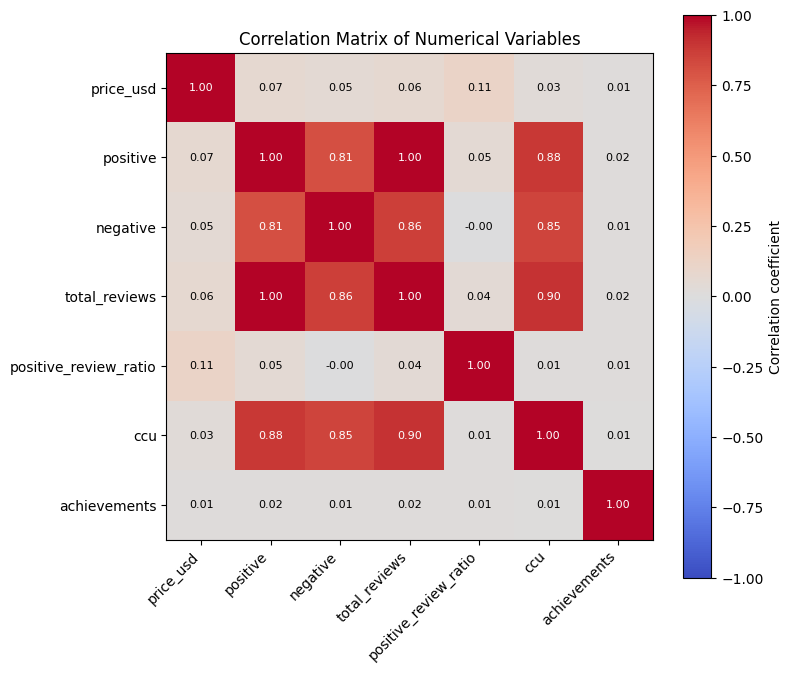

In [126]:
stats_cols = ['price_usd', 'positive', 'negative', 'total_reviews', 'positive_review_ratio', 'ccu', 'achievements']
corr_matrix = df[stats_cols].corr()

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)

ax.set_xticks(range(len(stats_cols)))
ax.set_yticks(range(len(stats_cols)))
ax.set_xticklabels(stats_cols, rotation=45, ha='right')
ax.set_yticklabels(stats_cols)

for i in range(len(stats_cols)):
    for j in range(len(stats_cols)):
        ax.text(j, i, f'{corr_matrix.iloc[i, j]:.2f}', ha='center', va='center',
                color='white' if abs(corr_matrix.iloc[i, j]) > 0.5 else 'black', fontsize=8)

ax.set_title('Correlation Matrix of Numerical Variables')
fig.colorbar(im, ax=ax, label='Correlation coefficient')

plt.tight_layout()
plt.show()

The heatmap shows the `positive_review_ratio` pattern isn't unique to `ccu` - it's fairly weak (between -0.00 and 0.11, using the raw/untransformed values shown here) against *every* other variable I have. The variables that are strongly correlated are all popularity/scale measures of each other: `ccu` correlates 0.85-0.90 with `positive`, `negative`, and `total_reviews`, and even `positive` and `negative` reviews are correlated at 0.81 - bigger, more exposed games rack up more of *both* positive and negative reviews, they don't trade off against each other.

So the raw numbers on this heatmap make it look like "how much attention a game got" (reviews, ccu) and "how much players actually liked it" (`positive_review_ratio`) barely relate to each other at all. But I already showed in the scatter plot above that this raw-correlation view is misleading for `ccu` specifically - once the skew is handled the relationship is weak-to-moderate (r = 0.234), not zero. I'd guess the same is probably true for `positive`/`negative`/`total_reviews` here too, since they're just as skewed - the heatmap is a useful first pass, but skewed count variables need a log transform before I fully trust a near-zero cell on it.

## Sampling: Does a sample tell the same story?

I'm picking `ccu` for this since it's my most extreme variable - almost all the popularity is concentrated in a tiny number of massively popular games (recall the histogram-of-outliers style pattern from earlier), so it's a good stress test for what happens when a small sample meets a heavily skewed variable.

In [127]:
population_mean = df['ccu'].mean()
print("Population mean (all games):", population_mean)

sample = df['ccu'].sample(n=30, random_state=10)

sample_mean = sample.mean()
sample_std = sample.std()
n = len(sample)
standard_error = sample_std / np.sqrt(n)

print("\nSample mean (n=30, random_state=10):", sample_mean)
print("Sample standard deviation:", sample_std)
print("Standard error:", standard_error)
print("\nDifference from population mean:", sample_mean - population_mean)

Population mean (all games): 252.5983813188271

Sample mean (n=30, random_state=10): 268.8333333333333
Sample standard deviation: 958.04535503224
Standard error: 174.91435068806777

Difference from population mean: 16.234952014506206


In [128]:
# evidence for the "would another student get the same mean" question -
# a couple more samples of 30 with different random_state values
for rs in range(1, 42):
    other_sample = df['ccu'].sample(n=30, random_state=rs)
    print(f"random_state={rs}: sample mean = {other_sample.mean():.2f}, sample max = {other_sample.max()}")

random_state=1: sample mean = 52.30, sample max = 618
random_state=2: sample mean = 504.00, sample max = 14345
random_state=3: sample mean = 780.07, sample max = 22757
random_state=4: sample mean = 26.80, sample max = 347
random_state=5: sample mean = 37.87, sample max = 598
random_state=6: sample mean = 132.93, sample max = 3725
random_state=7: sample mean = 46.07, sample max = 559
random_state=8: sample mean = 30.77, sample max = 300
random_state=9: sample mean = 91.30, sample max = 1153
random_state=10: sample mean = 268.83, sample max = 4845
random_state=11: sample mean = 18.53, sample max = 144
random_state=12: sample mean = 208.40, sample max = 5707
random_state=13: sample mean = 44.13, sample max = 1100
random_state=14: sample mean = 113.10, sample max = 3123
random_state=15: sample mean = 186.10, sample max = 4116
random_state=16: sample mean = 10.07, sample max = 85
random_state=17: sample mean = 43.67, sample max = 593
random_state=18: sample mean = 75.43, sample max = 2052
r

My sample mean (268.8) landed reasonably close to the population mean (252.6), but that's partly luck - the standard error is huge 174, which already signals that this particular sample isn't a very precise estimate.

**No, I would not expect another student to get exactly the same mean, and I wouldn't even expect them to get close.** The extra samples above make the point directly: `random_state=1` gives a mean of 52.30, but `random_state=41` gives a mean of only 2361.40 - 10 times more than of the population mean, all from the same population, same sample size, same variable. `ccu` is extremely right-skewed where most games have single-digit or zero concurrent players, but a some have six figures, so a sample of just 30 games is a coin flip on whether it happens to catch one of those rare massive outliers.

## One hypothesis test:

**Question:** The boxplot in the Visual Exploration section showed Paid games with a higher median `positive_review_ratio` than Free games (81.8% vs. 76.4%). Is that gap real, or could it just be random noise from which games happened to land in each group?

**H0 (null hypothesis):** The mean `positive_review_ratio` is the same for Free and Paid games.

**H1 (alternative hypothesis):** The mean `positive_review_ratio` is different for Free and Paid games.

**Test selected:** A two-sample t-test comparing the means of two independent groups (`positive_review_ratio` is numerical, `price_type` is categorical with two groups), the same test we used in class for comparing a numerical variable across two groups. I'm using `equal_var=False`, which doesn't assume the two groups have equal variance - appropriate here since Free (n=4,311) and Paid (n=18,273) are very different sizes and have slightly different standard deviations (17.4 vs. 18.5), so I don't want to assume they're equal.

In [129]:
free_ratio = df.loc[df['price_type'] == 'Free', 'positive_review_ratio'].dropna()
paid_ratio = df.loc[df['price_type'] == 'Paid', 'positive_review_ratio'].dropna()

print("Free: n =", len(free_ratio), " mean =", round(free_ratio.mean(), 2), " std =", round(free_ratio.std(), 2))
print("Paid: n =", len(paid_ratio), " mean =", round(paid_ratio.mean(), 2), " std =", round(paid_ratio.std(), 2))

t_stat, p_value = ttest_ind(paid_ratio, free_ratio, equal_var=False)

print("\nt-statistic:", t_stat)
print("p-value:", p_value)

Free: n = 4311  mean = 73.55  std = 17.39
Paid: n = 18273  mean = 77.56  std = 18.54

t-statistic: 13.43890185230799
p-value: 1.1748571645643838e-40


**Result:** t = 13.44, p ≈ 1.17 × 10⁻⁴⁰. Using α = 0.05, p is far below 0.05, so I **reject H0**.

**What this means:** The gap I saw in the boxplot is not random noise - Paid games really do have a higher average `positive_review_ratio` than Free games, and the difference is extremely statistically significant. That said, "statistically significant" isn't the same as "large" - a t-test with sample sizes this big (4,311 and 18,273) will detect even a modest difference as significant. The actual size of the gap is what I'd point to if someone asked how *meaningful* the difference is in practice, not just whether it exists. This confirms my Q3 boxplot finding was picking up a real pattern in the data, not just noise from how the games happened to split into groups.

# The most interesting finding:

My most interesting finding was how much a raw correlation number can hide. Going into this, my Q2 prediction was that positively-reviewed games would also be more engaging - more people currently playing them. The raw correlation between `positive_review_ratio` and `ccu` came out to just 0.012 - practically zero, which looked like a clean contradiction of my prediction.

But `ccu` is extremely skewed (skew stat of 113) - a handful of massively popular games completely dominate a raw correlation and drown out the pattern in the rest of the data. Once I log-transformed `ccu` to account for that skew, the correlation jumped to 0.234 - a real, if modest, positive relationship. That actually leans toward *supporting* my original prediction, not contradicting it.

The correlation heatmap backs this up from another angle: all the popularity-side variables (`positive`, `negative`, `total_reviews`, `ccu`) correlate strongly with *each other* (0.81-0.90), but only weakly with `positive_review_ratio` (-0.00 to 0.11). So popularity and reception aren't totally unrelated - they're just weakly related, and that relationship is easy to miss entirely if you trust a raw correlation without checking for skew first.

# What I Learned From This Dataset

The biggest lesson from this dataset had nothing to do with genre or price - it was that two of my three key variables (`average_forever` and `median_forever`, my intended playtime measures) turned out to be completely dead, all zeros, forcing me to rebuild my group-comparison and correlation questions around other variables (I also found `recommendations` was unreliable along the way and settled on `ccu` instead - see the data quality section). My most important finding was that review sentiment and engagement looked completely unrelated at first (raw correlation of 0.01), but that was because `ccu` is so skewed that a straight correlation hides the real pattern - once I log-transformed it, there was a real, if modest, positive relationship (r = 0.234), which actually leans toward *supporting* my Q2 prediction rather than contradicting it. My Q1 prediction (Action/RPG having higher engagement than casual genres) was loosely supported for the mean, but the group comparison showed that "high mean" mostly meant "a few huge hits," not a genuinely more engaged typical game - so the original prediction was right for the wrong reason. My Q3 prediction was partly wrong: paid games review significantly better than free games (confirmed with a t-test, p ≈ 10⁻⁴⁰), the opposite direction from what I expected, though I didn't get to test the "more current players" half of that prediction. One clear limitation of this analysis is `primary_genre`: reducing a multi-genre string down to just the first listed genre is a real simplification, and combined with the free/paid-by-genre confound I found, some of my group comparisons are probably tangled up with genre in ways I didn't fully untangle. If I had more time, I'd want to dig into what actually does predict engagement, and double-check whether the other popularity variables show the same skew-hides-a-real-relationship pattern I found with `ccu`.